In [1]:
!pip install -q kagglehub
import os, kagglehub
path = kagglehub.dataset_download("moltean/fruits")
print(path)

for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 3:
        print(root, "->", dirs[:5])


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\willi\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107 -> ['fruits-360_100x100', 'fruits-360_3-body-problem', 'fruits-360_meta', 'fruits-360_multi', 'fruits-360_original-size']
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107\fruits-360_100x100 -> ['fruits-360']
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107\fruits-360_100x100\fruits-360 -> ['Test', 'Training']
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107\fruits-360_100x100\fruits-360\Test -> ['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13']
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107\fruits-360_100x100\fruits-360\Training -> ['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13']
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107\fruits-360_3-body-problem -> ['fruits-360-3-body-problem']
C:\Users\willi\.cache\kagglehub\datasets\

In [2]:
DATA_DIR  = os.path.join(path, "fruits-360_100x100", "fruits-360")
TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR  = os.path.join(DATA_DIR, "Test")

print(len(os.listdir(TRAIN_DIR)), "classes in Training")
print(len(os.listdir(TEST_DIR)), "classes in Test")

268 classes in Training
268 classes in Test


## Settings
Run cell ONCE, don't re-run it between experiments.

In [11]:
import random

N_CLASSES = 40       # number of fruit classes to use (268 = all)
EPOCHS_HEAD = 3      # epochs with the pre-trained part frozen
EPOCHS_FINE = 3      # epochs while fine-tuning
SEED = 42

all_classes = sorted(os.listdir(TRAIN_DIR))
if N_CLASSES >= len(all_classes):
    chosen = all_classes
else:
    chosen = sorted(random.Random(SEED).sample(all_classes, N_CLASSES))

# Ignoring capitals
test_lookup = {name.lower(): name for name in os.listdir(TEST_DIR)}
chosen_test = [test_lookup[name.lower()] for name in chosen]
for a, b in zip(chosen, chosen_test):
    if a != b:
        print("name differs:", a, "vs", b)

results = []         # experiment log 
histories = {}       # history of each experiment
os.makedirs("results", exist_ok=True)
print(len(chosen), "classes chosen")

name differs: BlackBerry 4 vs Blackberry 4
40 classes chosen


## Load Data

In [12]:
%pip install -q scikit-learn matplotlib seaborn pandas
import tensorflow as tf
IMG = (224, 224); BS = 32
INPUT_SHAPE = IMG + (3,)
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=chosen, validation_split=0.2, subset="training", seed=42,
    image_size=IMG, batch_size=BS)
val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=chosen, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG, batch_size=BS)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, class_names=chosen_test, image_size=IMG, batch_size=BS, shuffle=False)
class_names = train_ds.class_names
print(len(class_names), "classes used")


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Found 20575 files belonging to 40 classes.
Using 16460 files for training.
Found 20575 files belonging to 40 classes.
Using 4115 files for validation.
Found 6862 files belonging to 40 classes.
40 classes used


## Data Exploration

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# How many training images does each class have?
counts = pd.Series({c: len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in chosen})
print("Images per class (Training folder):")
print("  min :", counts.min(), "->", counts.idxmin())
print("  max :", counts.max(), "->", counts.idxmax())
print("  mean:", round(counts.mean(), 1))

Images per class (Training folder):
  min : 149 -> Cabbage red 1
  max : 738 -> Cherry Rainier 1
  mean: 514.4


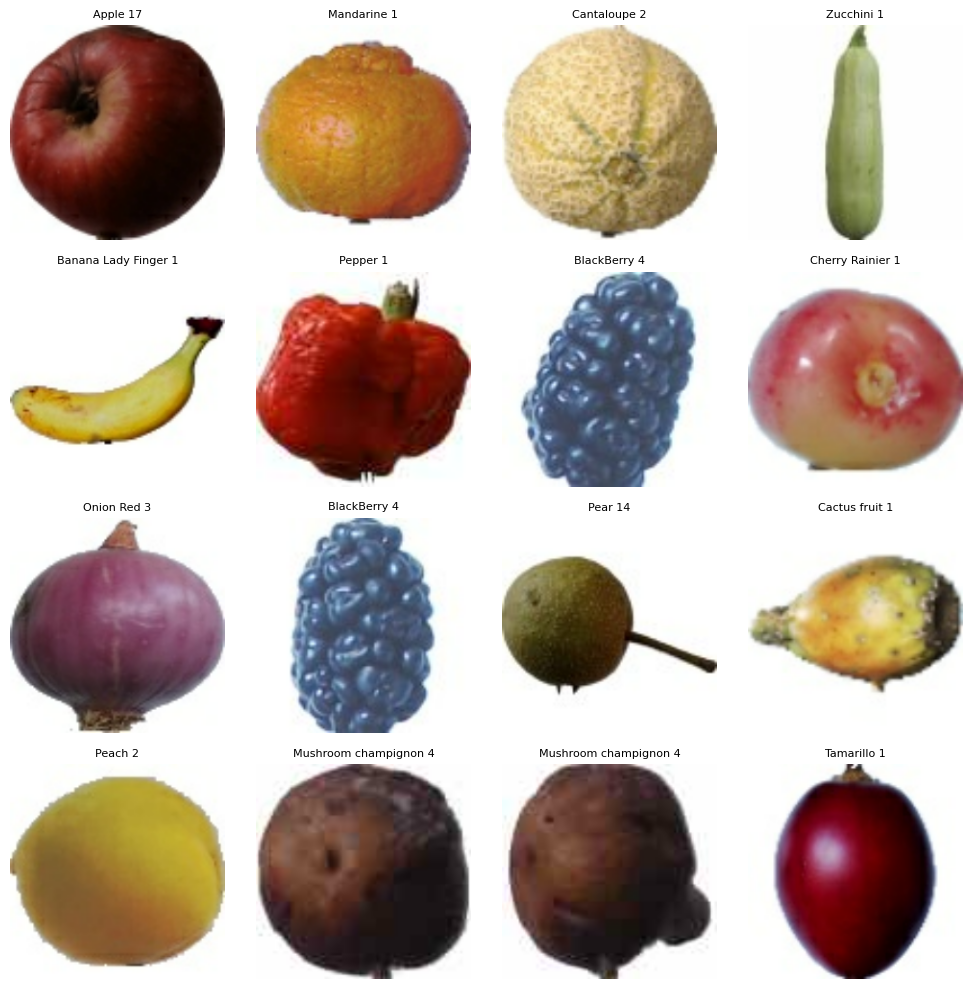

In [14]:
# Visualize some sample images from the training dataset
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()], fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.savefig("results/sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

## Data Augmentation

In [15]:
from tensorflow.keras import layers

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

## Models

In [ ]:
import time
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

# ----- EXPERIMENT SETTINGS: change ONE thing at a time, then run this cell -----
EXPERIMENT_NAME = "EfficientNetB0, with augmentation"
BACKBONE = "efficientnet"    # "efficientnet" or "resnet50"
USE_AUG = False              # True = augment the training images
DROPOUT = 0.3                # randomly switches off 30% of neurons while training to reduce overfitting
LR_FINE = 1e-5               # learning rate during fine-tuning
UNFREEZE = 30                # how many of the last layers of the pre-trained model to fine-tune
# -------------------------------------------------------------------------------

# 1. Load the pre-trained model, without its original classifier on top
if BACKBONE == "efficientnet":
    base_model = EfficientNetB0(include_top=False, weights="imagenet", input_shape=INPUT_SHAPE)
    preprocess = None                  
    last_conv = "top_activation"       # last convolution layer, used by Grad-CAM
else:
    base_model = ResNet50(include_top=False, weights="imagenet", input_shape=INPUT_SHAPE)
    preprocess = resnet_preprocess     # ResNet needs pixel scaling
    last_conv = "conv5_block3_out"

# 2. Prepare the data (augmentation only on training data)
def prepare(ds, augmenting=False):
    if augmenting:
        ds = ds.map(lambda x, y: (augment(x, training=True), y))
    if preprocess is not None:
        ds = ds.map(lambda x, y: (preprocess(x), y))
    return ds.prefetch(tf.data.AUTOTUNE)

train_data = prepare(train_ds, USE_AUG)
val_data = prepare(val_ds)
test_data = prepare(test_ds)

# 3. Freeze the pre-trained part and add own classifier on top
base_model.trainable = False
x = layers.GlobalAveragePooling2D()(base_model.output)
x = layers.Dropout(DROPOUT)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)   # one output per fruit class
model = tf.keras.Model(base_model.input, outputs)

# 4. Phase 1: train only the new classifier
start = time.time()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_head = model.fit(train_data, validation_data=val_data, epochs=EPOCHS_HEAD)

# 5. Phase 2: unfreeze the last layers and fine-tune with a small learning rate
base_model.trainable = True
for layer in base_model.layers[:-UNFREEZE]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False          
model.compile(optimizer=tf.keras.optimizers.Adam(LR_FINE),     # must compile again after changing trainable
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_fine = model.fit(train_data, validation_data=val_data, epochs=EPOCHS_FINE)
minutes = (time.time() - start) / 60

# 6. Test set result, saved to the results table
test_loss, test_acc = model.evaluate(test_data)
results.append({
    "experiment": EXPERIMENT_NAME,
    "classes": len(class_names),
    "val_acc": round(max(history_fine.history["val_accuracy"]), 4),
    "test_acc": round(test_acc, 4),
    "minutes": round(minutes, 1),
    "train_acc": round(history_fine.history["accuracy"][-1], 4),
    "gap": round(history_fine.history["accuracy"][-1] - history_fine.history["val_accuracy"][-1], 4),
})
print(f"{EXPERIMENT_NAME}: test accuracy {test_acc:.4f}, time {minutes:.1f} min")

histories[EXPERIMENT_NAME] = {
    "acc": history_head.history["accuracy"] + history_fine.history["accuracy"],
    "val_acc": history_head.history["val_accuracy"] + history_fine.history["val_accuracy"],
    "loss": history_head.history["loss"] + history_fine.history["loss"],
    "val_loss": history_head.history["val_loss"] + history_fine.history["val_loss"],
}

Epoch 1/3
515/515 ━━━━━━━━━━━━━━━━━━━━ 221s 415ms/step - accuracy: 0.9241 - loss: 0.4817 - val_accuracy: 0.9959 - val_loss: 0.0620
Epoch 2/3
515/515 ━━━━━━━━━━━━━━━━━━━━ 210s 408ms/step - accuracy: 0.9946 - loss: 0.0596 - val_accuracy: 0.9998 - val_loss: 0.0242
Epoch 3/3
515/515 ━━━━━━━━━━━━━━━━━━━━ 209s 406ms/step - accuracy: 0.9972 - loss: 0.0320 - val_accuracy: 1.0000 - val_loss: 0.0135
Epoch 1/3
515/515 ━━━━━━━━━━━━━━━━━━━━ 226s 426ms/step - accuracy: 0.9978 - loss: 0.0139 - val_accuracy: 1.0000 - val_loss: 0.0024
Epoch 2/3
515/515 ━━━━━━━━━━━━━━━━━━━━ 218s 423ms/step - accuracy: 0.9993 - loss: 0.0067 - val_accuracy: 1.0000 - val_loss: 0.0010
Epoch 3/3
515/515 ━━━━━━━━━━━━━━━━━━━━ 218s 424ms/step - accuracy: 0.9992 - loss: 0.0051 - val_accuracy: 1.0000 - val_loss: 7.3323e-04
215/215 ━━━━━━━━━━━━━━━━━━━━ 59s 274ms/step - accuracy: 1.0000 - loss: 9.9421e-04
EfficientNetB0, with augmentation: test accuracy 1.0000, time 21.7 min


## Training Curves

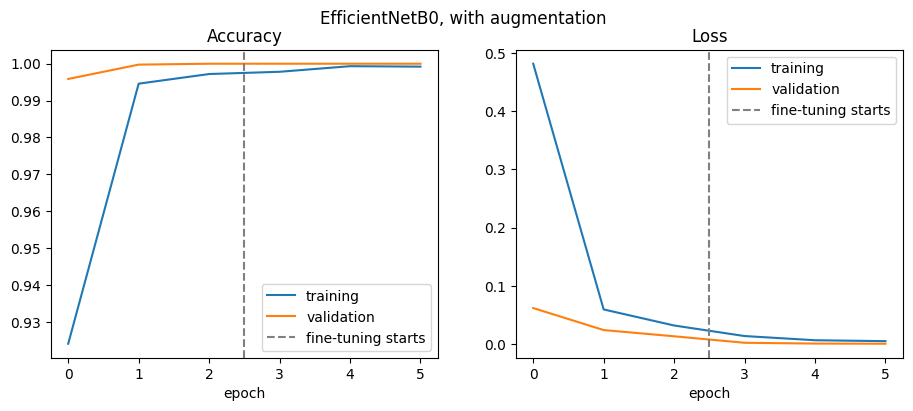

In [23]:
import matplotlib.pyplot as plt

acc = history_head.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history_head.history["val_accuracy"] + history_fine.history["val_accuracy"]
loss = history_head.history["loss"] + history_fine.history["loss"]
val_loss = history_head.history["val_loss"] + history_fine.history["val_loss"]
fine_start = len(history_head.history["accuracy"]) - 0.5     # epoch where fine-tuning begins

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(acc, label="training")
ax1.plot(val_acc, label="validation")
ax1.set_title("Accuracy")
ax2.plot(loss, label="training")
ax2.plot(val_loss, label="validation")
ax2.set_title("Loss")
for ax in (ax1, ax2):
    ax.axvline(fine_start, linestyle="--", color="gray", label="fine-tuning starts")
    ax.set_xlabel("epoch")
    ax.legend()
fig.suptitle(EXPERIMENT_NAME)
plt.savefig(f"results/curve_{EXPERIMENT_NAME}.png", dpi=150, bbox_inches="tight")
plt.show()

## Compare

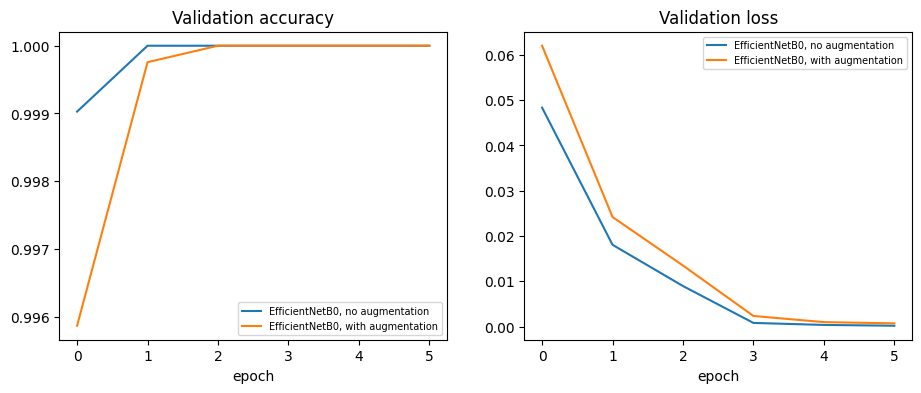

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, h in histories.items():
    ax1.plot(h["val_acc"], label=name)
    ax2.plot(h["val_loss"], label=name)
ax1.set_title("Validation accuracy"); ax2.set_title("Validation loss")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch"); ax.legend(fontsize=7)
plt.savefig("results/compare_experiments.png", dpi=150, bbox_inches="tight")
plt.show()